# Experiment 3 · Hold-period drift: pulled to the centre or to the target?

**Date:** 2026-11-07 · **Agents:** `baseline_s1`–`baseline_s8` · **Status:** 8 seeds

## Question
Experiment 2 found that from an off-centre start the mass drifts during the hold, and that
far starts end in false starts. In 9 of 10 of those trials, "towards the centre" and
"towards the target" pointed the same way, so they could not tell apart two explanations:

1. **centre pull**: the hold was learned as "stay near x = 0", because in training the
   start is always x = 0;
2. **target pull**: the agent leaks movement towards the visible target before the go cue
   (it already does this slightly from x = 0, see Experiment 1).

Two follow-up questions came from looking at the trials: if it is a centre pull, *why is it
slow* rather than a rush back to the centre, and *why is it stronger from further away*?

## Design
- Starts x₀ ∈ {−0.8, −0.6, …, +0.8} (9 positions).
- For each start, targets at offsets {−0.4, −0.2, +0.2, +0.4} from it, kept inside ±0.9.
  The key conditions are the **outward** ones: the target is on the same side as the start
  and further from the centre, so the centre pull and the target pull point in opposite
  directions.
- **3 s hold, false-start abort switched off**, so we see where the policy takes the mass
  instead of stopping at the 0.15 abort line. Training holds last at most 1 s, so anything
  after 1 s (shaded in the plots) is outside the training distribution as well.
- Noiseless plant, mean action. All 8 baseline seeds.

### Measures
- `v_0.3s`: drift velocity 0.3 s into the hold (early, well inside the trained hold length).
- A linear split of that drift into two terms:
  **v = b_centre · x₀ + b_target · (target − x₀) + c**.
  b_centre < 0 is a pull back to x = 0 that grows with distance from it; b_target > 0 is a
  pull towards the target that grows with the target's distance.
- For the outward conditions: the fraction where the mass drifts towards the centre (and so
  away from the target).

In [1]:
from exp_tools import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Video, display
from single_target_video import make_video, outcome

use_style()
pd.set_option("display.precision", 3)

In [2]:
results, trajs = [], {}
for s in SEEDS:
    df, traj, dt, hold = hold_probe(RUNS / f"baseline_s{s}")
    df["seed"] = s
    results.append(df)
    trajs[s] = traj
res = pd.concat(results, ignore_index=True)
print(f"{len(res)} conditions ({len(res) // len(SEEDS)} per seed × {len(SEEDS)} seeds)")
res.groupby("side").size().rename("conditions")

240 conditions (30 per seed × 8 seeds)


side
centre      32
inward     128
outward     80
Name: conditions, dtype: int64

## 1 · The decisive test: outward targets

In these conditions the target is further out than the start. A centre pull moves the mass *away* from the target; a target pull moves it *towards* the target.

In [3]:
out = res[res.side == "outward"]
summary = out.groupby("seed").agg(
    n=("drift_to_centre", "size"),
    to_centre=("drift_to_centre", "sum"),
    mean_v=("v_0.3s", lambda v: np.mean(np.abs(v))))
summary["fraction to centre"] = summary.to_centre / summary.n
summary

,n,to_centre,mean_v,fraction to centre
seed,,,,
1,10,10.0,0.119,1.0
2,10,10.0,0.072,1.0
3,10,5.0,0.044,0.5
4,10,9.0,0.035,0.9
5,10,10.0,0.095,1.0
6,10,10.0,0.076,1.0
7,10,10.0,0.018,1.0
8,10,1.0,0.032,0.1


## 2 · Splitting the drift into a centre term and a target term

In [4]:
fits = pd.DataFrame([{"seed": s, **drift_fit(res[res.seed == s])} for s in SEEDS]).set_index("seed")
fits["centre/target ratio"] = -fits.b_centre / fits.b_target
display(fits)
print("mean ± sd over seeds:")
display(fits[["b_centre", "b_target", "R2"]].agg(["mean", "std"]))

,b_centre,b_target,c,R2,centre/target ratio
seed,,,,,
1,-0.395,0.080,-0.008,0.999,4.953
2,-0.202,-0.005,0.009,0.990,-40.157
3,-0.072,0.085,-0.020,0.793,0.852
4,-0.162,0.071,-0.008,0.989,2.265
5,-0.297,0.034,0.027,0.990,8.627
6,-0.206,-0.012,0.012,0.995,-17.880
7,-0.062,0.011,0.012,0.876,5.425
8,0.036,0.049,-0.016,0.783,-0.744


mean ± sd over seeds:


,b_centre,b_target,R2
mean,-0.170,0.039,0.927
std,0.138,0.038,0.095


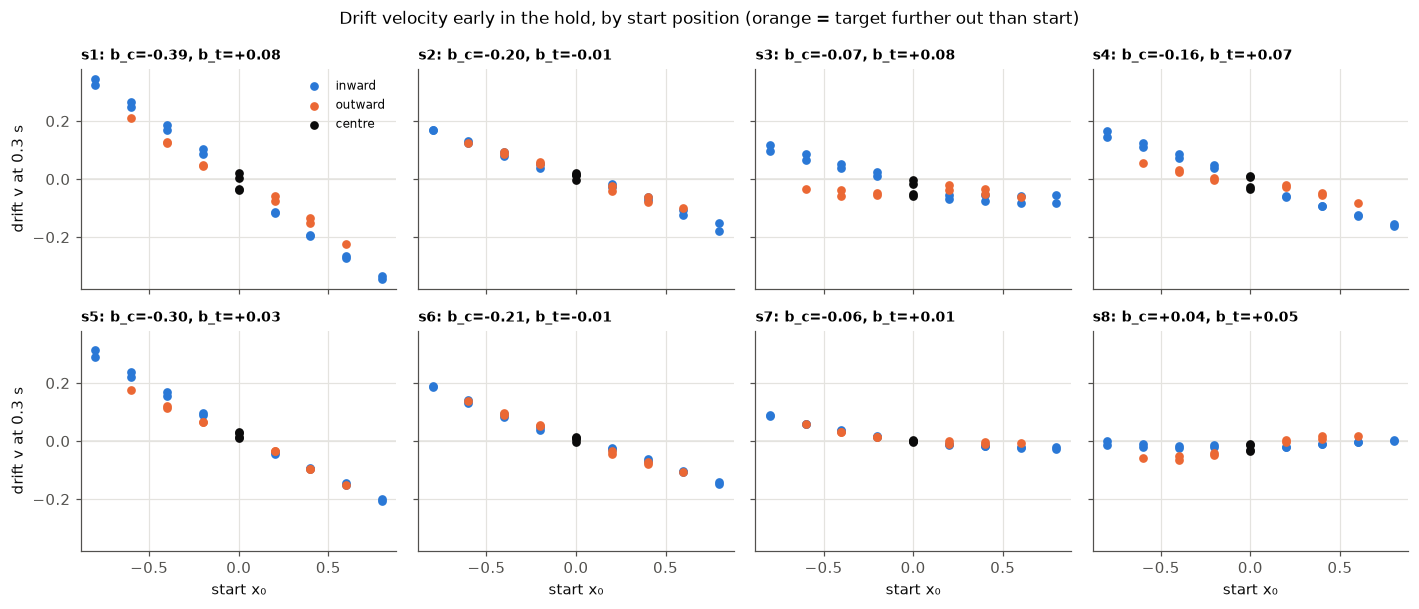

In [5]:
fig, axs = plt.subplots(2, 4, figsize=(13, 5.6), sharex=True, sharey=True)
for ax, s in zip(axs.flat, SEEDS):
    d = res[res.seed == s]
    for side, col in (("inward", BLUE), ("outward", ORANGE), ("centre", INK)):
        e = d[d.side == side]
        ax.scatter(e.x0, e["v_0.3s"], s=22, color=col, label=side, zorder=3)
    f = fits.loc[s]
    ax.axhline(0, color=GRID, lw=1)
    ax.set_title(f"s{s}: b_c={f.b_centre:+.2f}, b_t={f.b_target:+.2f}", fontsize=9)
for ax in axs[1]: ax.set_xlabel("start x₀")
for ax in axs[:, 0]: ax.set_ylabel("drift v at 0.3 s")
axs[0, 0].legend(fontsize=8, loc="upper right")
fig.suptitle("Drift velocity early in the hold, by start position (orange = target further out than start)", fontsize=11)
plt.tight_layout(); plt.show()

## 3 · Where does the mass go, and how fast?

Position during the 3 s hold for one seed, outward-target conditions only (offset 0.4 away from the centre), one line per start. The shaded region is beyond the longest trained hold (1 s).

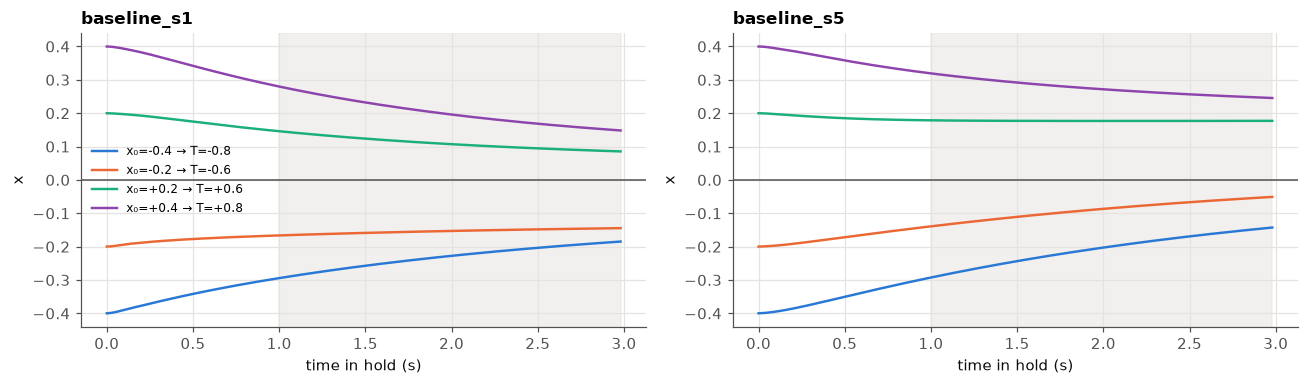

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, s in zip(axs, (1, 5)):
    d = res[res.seed == s].reset_index(drop=True)
    tr = trajs[s]
    t = np.arange(hold) * dt
    sel = d[(d.side == "outward") & (d.offset.abs() == 0.4)]
    for (i, r), col in zip(sel.iterrows(), [BLUE, ORANGE, AQUA, "#8e44ad"]):
        ax.plot(t, tr["x"][:hold, i], lw=1.6, color=col,
                label=f"x₀={r.x0:+.1f} → T={r.target:+.1f}")
    ax.axhline(0, color=INK_SOFT, lw=1)
    ax.axvspan(1.0, t[-1], color=GRID, alpha=0.5)
    ax.set_xlabel("time in hold (s)"); ax.set_ylabel("x")
    ax.set_title(f"baseline_s{s}")
axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [7]:
# How strongly does each seed push at the start, as a function of distance from the centre?
early = res[res.x0 != 0].groupby(["seed", "x0"])["u_early"].mean().unstack("seed")
early.round(2)

seed,1,2,3,4,5,6,7,8
x0,,,,,,,,
-0.8,3.26,1.11,0.65,1.14,2.09,1.45,0.54,0.13
-0.6,2.49,0.78,0.29,0.74,1.46,1.11,0.39,-0.04
-0.4,1.72,0.50,0.05,0.42,0.92,0.75,0.25,-0.12
-0.2,0.97,0.22,-0.07,0.17,0.46,0.36,0.12,-0.08
0.2,-0.53,-0.38,-0.25,-0.31,-0.44,-0.38,-0.03,0.07
0.4,-1.23,-0.69,-0.29,-0.54,-0.88,-0.73,-0.05,0.16
0.6,-1.94,-1.00,-0.31,-0.83,-1.28,-1.02,-0.05,0.21
0.8,-2.66,-1.40,-0.26,-1.19,-1.66,-1.32,-0.06,0.22


## 4 · How much does the centre pull matter inside the trained hold length?

For each start, whether the mass crosses the 0.15 false-start line within the first 1 s (the longest trained hold), averaged over targets and seeds.

In [8]:
fs = res.groupby("x0")["false_start_by_1s"].mean().rename("P(false start within 1 s)")
fs.to_frame().T.round(2)

x0,-0.8,-0.6,-0.4,-0.2,-0.0,0.2,0.4,0.6,0.8
P(false start within 1 s),0.56,0.25,0.06,0.0,0.0,0.0,0.06,0.12,0.31


## Conclusion

**A centre bias exists in 7 of 8 seeds, but its strength varies about tenfold, and one seed
has none.**

| seed | b_centre (1/s) | outward conditions drifting to centre | verdict |
| --- | --- | --- | --- |
| s1 | −0.40 | 10/10 | strong centre pull |
| s5 | −0.30 | 10/10 | strong |
| s6 | −0.21 | 10/10 | moderate |
| s2 | −0.20 | 10/10 | moderate |
| s4 | −0.16 | 9/10 | moderate |
| s3 | −0.07 | 5/10 | weak, one-sided |
| s7 | −0.06 | 10/10 | weak (drifts are tiny) |
| s8 | +0.04 | 1/10 | **none** (target pull only) |

Mean b_centre = −0.17 ± 0.14 /s (sd over seeds).

1. **Centre, not target, is the main pull off-centre.** In the outward conditions, where the
   two point in opposite directions, 5 seeds drift towards the centre in every condition. The
   target pull is real but smaller (b_target ≈ +0.03 to +0.085 in s1, s3, s4, s5 and s8; about
   0 in s2, s6 and s7).
2. **Why slow, and why stronger when far.** In the strong seeds the drift is proportional to
   the distance from the centre (linear fit R² ≥ 0.99 in s1, s2, s4, s5 and s6). The opening
   push is proportional too (force table, section 3). This is proportional feedback: a gentle
   rule that the network uses near x = 0, extrapolated to positions it never visited during a
   hold. The rate (0.06–0.4 /s, a time constant of roughly 2.5 s to well over 10 s) is far
   slower than any deliberate return, so "stay at x = 0" was too strong a description. It is
   **not a point attractor at 0 in every seed** either: in s5, a start at +0.2 settles at
   about +0.18 and stays there.
   *That this is extrapolation of an under-trained rule is an interpretation that fits the
   data, not something this experiment proves.*
3. **The seeds disagree, and that is itself informative.** Training never constrains what the
   hold does away from x = 0, so each seed fills that gap differently. s3 and s7 push back only
   from negative starts, and s8 does not push back at all. The linear fit is poor for those
   seeds (R² 0.78–0.88).
4. **Practical consequence.** Within the trained hold length (1 s), averaged over seeds and
   targets, a false start occurs from 56% of starts at −0.8 and 31% at +0.8, but from ≤ 6% at
   |x₀| ≤ 0.4. **Off-centre probes are safe within about ±0.4 of the centre**; beyond that, hold
   failures will contaminate them in the seeds with a strong pull.

*Limits: noiseless plant and mean action; the probe applies a hold rule the agent never
trained on; anything after 1 s of hold is outside training; the two-term linear model is a
summary, not a mechanism.*